In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia.dataset import cargar_datos_modelo
from energia.entrenamiento import (fijar_semilla, dispositivo, contar_parametros, entrenar, predecir,
                                   guardar_modelo, guardar_resultados)
from energia.metricas import evaluar, error_por_hora, naive_estacional, tabla
from energia.modelos import gru
from energia.visualizacion import estilo, guardar_figura, curvas_aprendizaje, pronostico_vs_real

estilo()
NOMBRE = "gru"
fijar_semilla()
print("torch", torch.__version__, "| dispositivo:", dispositivo())

torch 2.5.1+cpu | dispositivo: cpu


In [2]:
datos = cargar_datos_modelo()
datos.resumen()

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [3]:
HP_MODELO = {"oculto": 48, "capas": 2, "dropout": 0.15, "atencion": 32, "cabeza": 64, "corregir_naive": False}
HP_ENTRENAMIENTO = {"optimizador": "adam", "lr": 1e-3, "epocas": 50, "batch": 256, "paciencia": 8, "clip": 1.0}

modelo = gru.construir(datos, **HP_MODELO)
print(modelo)
print("parámetros entrenables:", contar_parametros(modelo))

GRUPronostico(
  (gru): GRU(16, 48, num_layers=2, batch_first=True, dropout=0.15)
  (consulta): Linear(in_features=57, out_features=32, bias=True)
  (clave): Linear(in_features=48, out_features=32, bias=False)
  (cabeza): Sequential(
    (0): Linear(in_features=109, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
parámetros entrenables: 34178


In [4]:
historial = entrenar(modelo, datos, **HP_ENTRENAMIENTO)

época   1 | train 0.2776 | val 0.2131 | 416.0 s *
época   2 | train 0.1238 | val 0.1769 | 344.7 s *
época   3 | train 0.1048 | val 0.1578 | 323.1 s *
época   4 | train 0.0941 | val 0.1575 | 409.5 s *
época   5 | train 0.0865 | val 0.1473 | 331.0 s *
época   6 | train 0.0821 | val 0.1445 | 350.6 s *
época   7 | train 0.0785 | val 0.1404 | 340.1 s *
época   8 | train 0.0761 | val 0.1459 | 286.6 s
época   9 | train 0.0736 | val 0.1495 | 311.8 s
época  10 | train 0.0717 | val 0.1523 | 289.3 s
época  11 | train 0.0699 | val 0.1504 | 291.3 s
época  12 | train 0.0684 | val 0.1548 | 249.6 s
época  13 | train 0.0668 | val 0.1541 | 263.7 s
época  14 | train 0.0653 | val 0.1521 | 255.7 s
época  15 | train 0.0639 | val 0.1628 | 275.8 s
Early stopping: 8 épocas sin mejorar en validación.


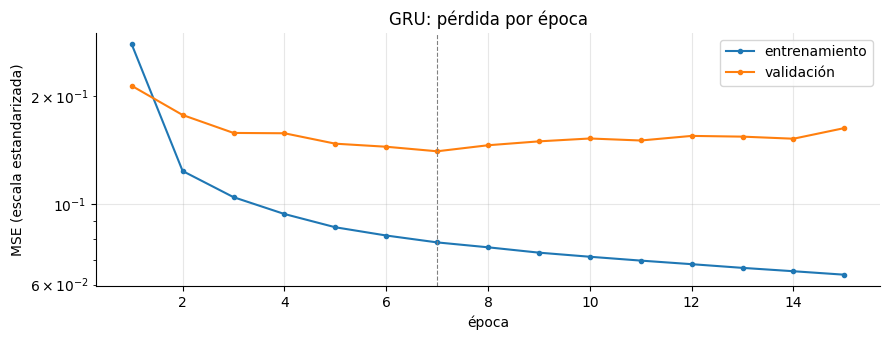

,train,val,segundos
epoca,,,
7,0.078528,0.140381,340.13854


In [5]:
fig = curvas_aprendizaje(historial, "GRU: pérdida por época")
guardar_figura(fig, "f2_03_gru_curvas")
plt.show()
historial.loc[[historial["val"].idxmin()]]

In [6]:
resultados = {}
predicciones = {}
for split in ["val", "test"]:
    y = datos.y_original(split)
    predicciones[split] = predecir(modelo, datos, split)
    resultados[("gru", split)] = evaluar(y, predicciones[split])
    resultados[("naive_m24", split)] = evaluar(y, naive_estacional(datos, split, m=24))
    resultados[("naive_m168", split)] = evaluar(y, naive_estacional(datos, split, m=168))

metricas = tabla(resultados)
metricas.index = pd.MultiIndex.from_tuples(metricas.index, names=["modelo", "split"])
metricas.sort_index()

demanda_MAE  precio_MAE   demanda_RMSE  precio_RMSE  \
modelo     split                                                          
gru        test    78159.652619   65.742674  101582.349809   105.630677   
           val     71663.598072   52.586933   97561.700384    99.808307   
naive_m168 test   121128.936093  126.488172  201826.283211   182.248794   
           val    111762.365881   81.734684  179377.523882   136.076668   
naive_m24  test   194816.646206   56.109531  273062.870794   111.123112   
           val    194135.892010   48.523627  274407.867423   111.794765   

                  demanda_MAPE_%  precio_MAPE_%  demanda_R2  precio_R2  
modelo     split                                                        
gru        test         2.588732      16.386408    0.871185   0.892543  
           val          2.409034      23.550623    0.864018   0.582332  
naive_m168 test         4.059732      34.665457    0.491508   0.680121  
           val          3.833292      37.448509    0.540316   0.223636  
naive_m24  test         6.670997      14.863168    0.069204   0.881077  
           val          6.718642      20.336838   -0.075762   0.475988

In [7]:
metricas.loc[(slice(None), "val"), ["demanda_MAPE_%", "precio_MAPE_%", "demanda_MAE", "precio_MAE"]]

,,demanda_MAPE_%,precio_MAPE_%,demanda_MAE,precio_MAE
modelo,split,,,,
gru,val,2.409034,23.550623,71663.598072,52.586933
naive_m24,val,6.718642,20.336838,194135.892010,48.523627
naive_m168,val,3.833292,37.448509,111762.365881,81.734684


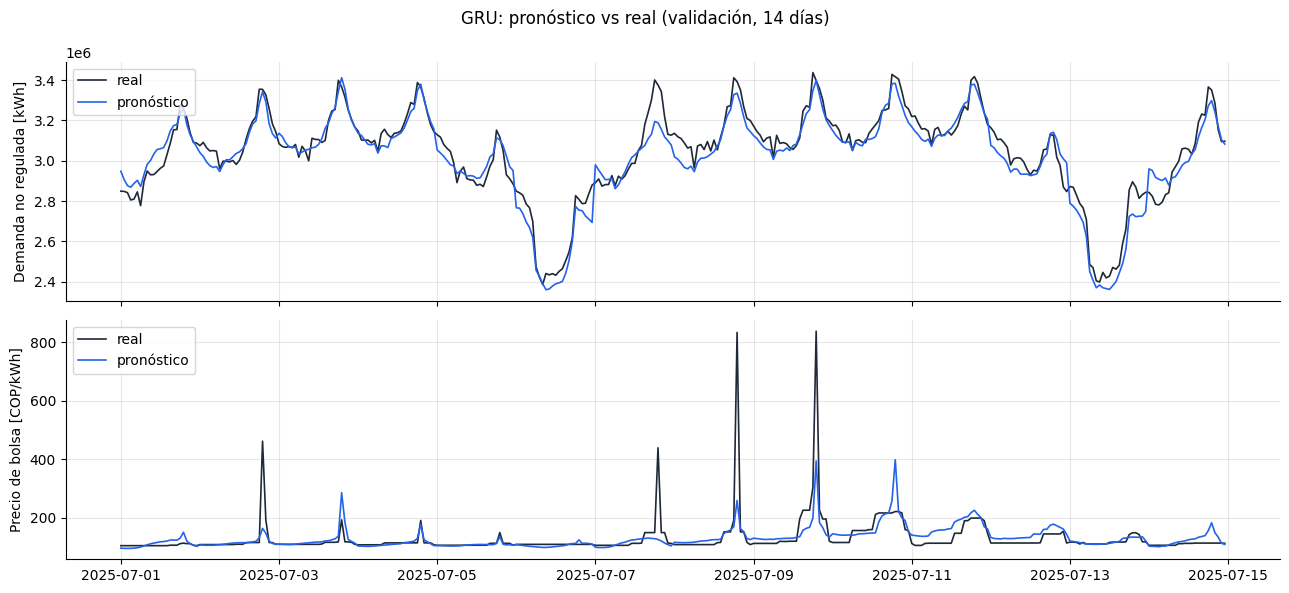

In [8]:
fig = pronostico_vs_real(datos, predicciones["val"], "val", dias=14, titulo="GRU: pronóstico vs real (validación, 14 días)")
guardar_figura(fig, "f2_03_gru_pronostico_val")
plt.show()

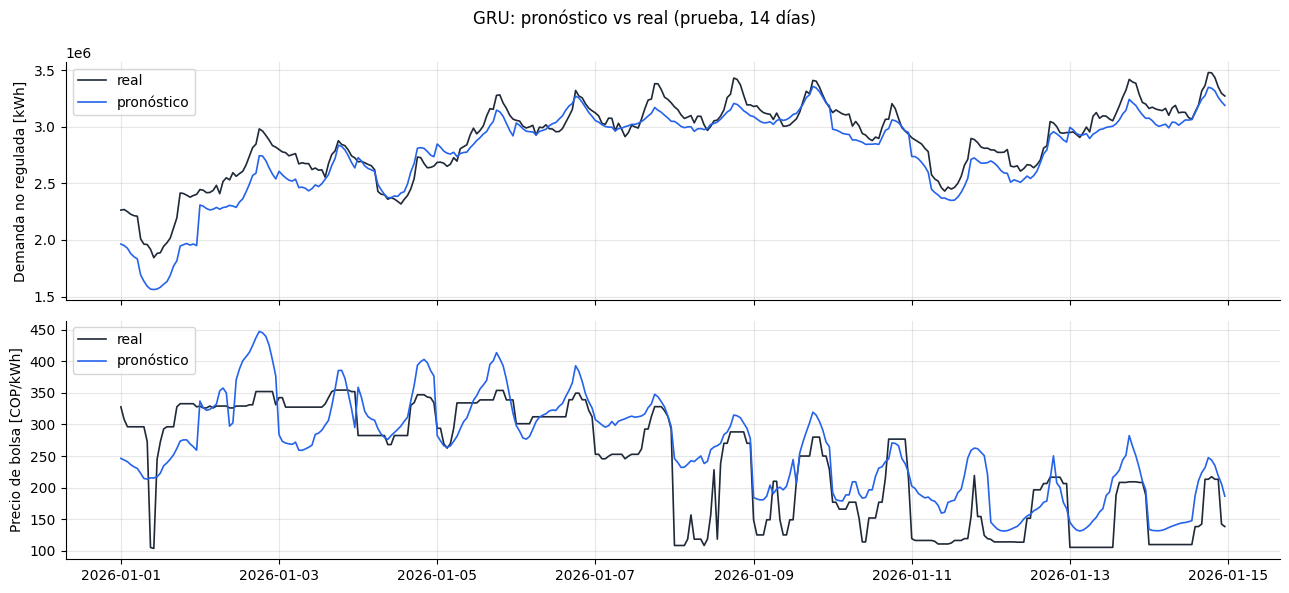

In [9]:
fig = pronostico_vs_real(datos, predicciones["test"], "test", dias=14, titulo="GRU: pronóstico vs real (prueba, 14 días)")
guardar_figura(fig, "f2_03_gru_pronostico_test")
plt.show()

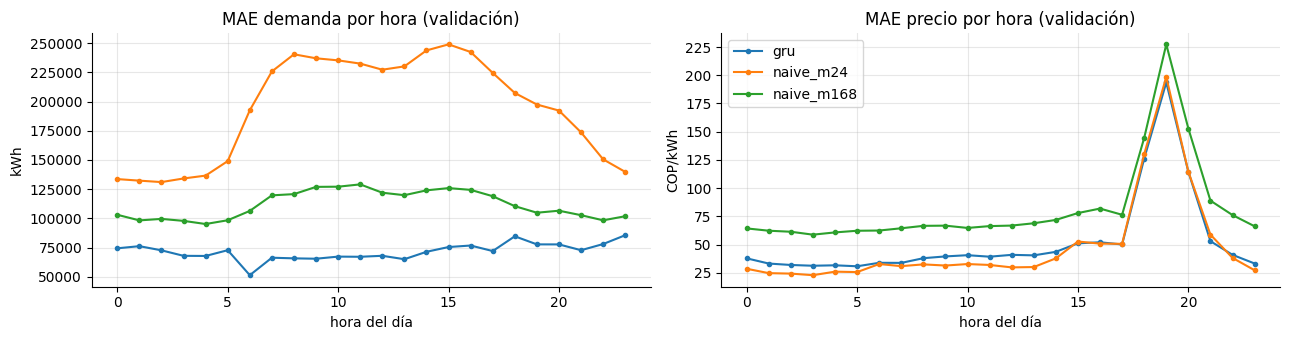

In [10]:
y_val = datos.y_original("val")
errores = {
    "gru": error_por_hora(y_val, predicciones["val"]),
    "naive_m24": error_por_hora(y_val, naive_estacional(datos, "val", m=24)),
    "naive_m168": error_por_hora(y_val, naive_estacional(datos, "val", m=168)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre, e in errores.items():
    axes[0].plot(e.index - 1, e["demanda"], marker=".", label=nombre)
    axes[1].plot(e.index - 1, e["precio"], marker=".", label=nombre)
axes[0].set(title="MAE demanda por hora (validación)", xlabel="hora del día", ylabel="kWh")
axes[1].set(title="MAE precio por hora (validación)", xlabel="hora del día", ylabel="COP/kWh")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "f2_03_gru_error_por_hora")
plt.show()

In [11]:
hiperparametros = {**HP_MODELO, **HP_ENTRENAMIENTO, "parametros": contar_parametros(modelo),
                   "mejor_epoca": int(historial["val"].idxmin()), "epocas_entrenadas": len(historial)}
print(guardar_modelo(modelo, NOMBRE, hiperparametros))
print(guardar_resultados(NOMBRE, metricas, hiperparametros, historial))

C:\Users\57310\Desktop\pronostico-energia-nr\pronostico-energia-nr\results\modelos\gru.pt
C:\Users\57310\Desktop\pronostico-energia-nr\pronostico-energia-nr\results\fase2\gru
